# BIKE-DYNAMICS — Tahap 7: Sensitivity Analysis
**Judul Penelitian:** *Pemodelan dan Simulasi Sistem Dinamik untuk Optimalisasi Ketersediaan Armada Sepeda pada Layanan Bike Sharing Berdasarkan Fluktuasi Permintaan dan Kondisi Cuaca*  
**Platform Pendamping:** `BIKE-DYNAMICS – Dynamic System Simulation for Bike Sharing Management`  
**Mata Kuliah:** Pemodelan dan Simulasi (UTS)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UTS-MOSI/bike-dynamics/blob/main/notebooks/07_sensitivity_analysis.ipynb)

---
### Analisis Sensitivitas Parameter Operasional terhadap Kinerja Sistem Bike Sharing


In [1]:
# 1. Setup Lingkungan Eksekusi (Google Colab / Lokal)
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Menjalankan di Google Colab. Memasang pustaka pendukung...")
    !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib nbformat
else:
    print("Menjalankan di lingkungan lokal Python.")


Menjalankan di lingkungan lokal Python.


In [2]:
# 2. Konfigurasi Direktori Kerja & Deteksi Path Otomatis
import os
from pathlib import Path

if IN_COLAB:
    # Opsi jika menggunakan Google Drive:
    # from google.colab import drive
    # drive.mount('/content/drive')
    # PROJECT_ROOT = Path('/content/drive/MyDrive/BIKE-DYNAMICS')
    
    colab_default = Path('/content/bike-dynamics')
    colab_alt = Path('/content/BIKE-DYNAMICS-COLAB')
    colab_content = Path('/content')
    
    if (colab_default / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_default
    elif (colab_alt / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_alt
    elif (colab_content / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_content
    elif (colab_content / 'train.csv').exists():
        PROJECT_ROOT = colab_content
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
        import shutil
        if not (PROJECT_ROOT / 'data' / 'raw' / 'train.csv').exists():
            shutil.copy(colab_content / 'train.csv', PROJECT_ROOT / 'data' / 'raw' / 'train.csv')
    else:
        PROJECT_ROOT = colab_default
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
else:
    cwd = Path.cwd()
    if (cwd / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd
    elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd.parent
    else:
        PROJECT_ROOT = cwd

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'

(PROJECT_ROOT / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root  : {PROJECT_ROOT}")
print(f"Raw Data Path : {RAW_DATA_PATH} (Tersedia: {RAW_DATA_PATH.exists()})")


Project Root  : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics
Raw Data Path : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\raw\train.csv (Tersedia: True)


## 3. Landasan Teori: Analisis Sensitivitas One-at-a-Time (OAT)
Dalam pemodelan sistem dinamik, parameter seperti tingkat kerusakan ($\alpha_d$), durasi perbaikan ($\tau_m$), durasi penyewaan ($\tau_r$), dan kapasitas total armada ($B_{\text{total}}$) sering kali berasal dari estimasi atau asumsi peneliti.

Analisis sensitivitas bertujuan untuk:
1. Mengidentifikasi parameter yang memiliki pengaruh paling signifikan terhadap metrik kinerja (*Service Level*, *Unmet Demand*, *Utilisasi Armada*).
2. Menguji ketahanan kebijakan terhadap ketidakpastian kondisi operasional.
3. Menghitung **Indeks Elastisitas Sensitivitas**:
   $$\epsilon = \frac{(Y_{\max} - Y_{\min}) / Y_{\text{base}}}{(X_{\max} - X_{\min}) / X_{\text{base}}}$$


In [3]:
# 4. Import Library & Load Horizon Simulasi
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (14, 5.5)

sim_input_df = pd.read_csv(ARTIFACTS_DIR / 'simulation_horizon_input.csv')
with open(ARTIFACTS_DIR / 'sd_assumptions.json', 'r') as f:
    base_assumptions = json.load(f)

FIGURES_DIR = ARTIFACTS_DIR / 'sd_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Horizon Simulasi: {len(sim_input_df)} jam.")
print(f"Asumsi Dasar     : {base_assumptions}")


Horizon Simulasi: 168 jam.
Asumsi Dasar     : {'total_fleet': 600.0, 'initial_available': 510.0, 'initial_rented': 60.0, 'initial_maintenance': 30.0, 'rental_duration_hours': 1.5, 'damage_rate': 0.04, 'repair_duration_hours': 6.0, 'demand_multiplier': 1.0, 'weather_damage_multipliers': {'1': 1.0, '2': 1.1, '3': 1.35, '4': 1.6}}


## 5. Implementasi Mesin Simulasi Sensitivitas & Grid Parameter
Lima parameter operasional utama yang diuji:
1. **Damage Rate ($\alpha_d$):** `[0.01, 0.02, 0.04, 0.06, 0.08, 0.12]` (Fraksi kerusakan).
2. **Repair Duration ($\tau_m$):** `[2.0, 3.0, 4.0, 6.0, 10.0, 16.0]` jam (Kecepatan penanganan bengkel).
3. **Rental Duration ($\tau_r$):** `[1.0, 1.25, 1.5, 2.0, 2.5, 3.0]` jam (Lama penggunaan per sewa).
4. **Fleet Capacity ($B_{\text{total}}$):** `[450, 525, 600, 675, 750, 825]` unit (Ukuran investasi armada).
5. **Demand Multiplier ($\mu_D$):** `[0.8, 0.9, 1.0, 1.1, 1.2, 1.35]` (Volatilitas pasar/cuaca).


In [4]:
# Definisi Simulator Ringan untuk Sensitivitas
def run_simulation(params, demand_series, weather_series):
    total_fleet = float(params['total_fleet'])
    ba = float(params.get('initial_available', total_fleet * 0.85))
    br = float(params.get('initial_rented', total_fleet * 0.10))
    bm = float(params.get('initial_maintenance', total_fleet * 0.05))
    dt = 1.0

    ret_frac = min(1.0, dt / max(float(params['rental_duration_hours']), 0.1))
    rep_frac = min(1.0, dt / max(float(params['repair_duration_hours']), 0.1))
    d_mult = float(params.get('demand_multiplier', 1.0))
    d_arr = np.asarray(demand_series, dtype=float) * d_mult
    w_arr = np.asarray(weather_series, dtype=int)
    w_map = {1: 1.0, 2: 1.10, 3: 1.35, 4: 1.60}

    total_rentals = 0.0
    total_demand = float(d_arr.sum())
    total_unmet = 0.0
    ba_list, br_list, bm_list = [], [], []

    for t in range(len(d_arr)):
        d = max(0.0, float(d_arr[t]))
        w_factor = w_map.get(int(w_arr[t]), 1.0)

        r = min(ba, d)
        unmet = max(0.0, d - r)
        u = br * ret_frac
        m_in = u * min(0.95, float(params['damage_rate']) * w_factor)
        m_out = bm * rep_frac

        ba = max(0.0, ba - r + u - m_in + m_out)
        br = max(0.0, br + r - u)
        bm = max(0.0, bm + m_in - m_out)

        total_rentals += r
        total_unmet += unmet
        ba_list.append(ba)
        br_list.append(br)
        bm_list.append(bm)

    service_level = (total_rentals / total_demand * 100.0) if total_demand > 0 else 100.0
    avg_util = (np.mean(br_list) / total_fleet * 100.0) if total_fleet > 0 else 0.0

    return {
        'total_demand': round(total_demand, 2),
        'total_rentals': round(total_rentals, 2),
        'total_unmet_demand': round(total_unmet, 2),
        'service_level_pct': round(service_level, 2),
        'avg_available': round(float(np.mean(ba_list)), 2),
        'avg_maintenance': round(float(np.mean(bm_list)), 2),
        'avg_utilization_pct': round(avg_util, 2)
    }

sensitivity_grids = {
    'fleet_capacity': {
        'param_key': 'total_fleet',
        'label': 'Kapasitas Total Armada (Fleet Capacity)',
        'unit': 'Sepeda',
        'base_val': 600.0,
        'values': [450.0, 525.0, 600.0, 675.0, 750.0, 825.0]
    },
    'demand_multiplier': {
        'param_key': 'demand_multiplier',
        'label': 'Perubahan Permintaan (Demand Multiplier)',
        'unit': 'Pengali',
        'base_val': 1.0,
        'values': [0.8, 0.9, 1.0, 1.1, 1.2, 1.35]
    },
    'repair_duration': {
        'param_key': 'repair_duration_hours',
        'label': 'Durasi Perbaikan (Repair Duration)',
        'unit': 'Jam',
        'base_val': 6.0,
        'values': [2.0, 3.0, 4.0, 6.0, 10.0, 16.0]
    },
    'damage_rate': {
        'param_key': 'damage_rate',
        'label': 'Tingkat Kerusakan (Damage Rate)',
        'unit': 'Fraksi',
        'base_val': 0.04,
        'values': [0.01, 0.02, 0.04, 0.06, 0.08, 0.12]
    },
    'rental_duration': {
        'param_key': 'rental_duration_hours',
        'label': 'Durasi Sewa (Rental Duration)',
        'unit': 'Jam',
        'base_val': 1.5,
        'values': [1.0, 1.25, 1.5, 2.0, 2.5, 3.0]
    }
}
print("Grid 5 parameter sensitivitas siap.")


Grid 5 parameter sensitivitas siap.


## 6. Eksekusi 30 Skenario Sensitivitas OAT

In [5]:
# Menjalankan Eksperimen Sensitivitas
all_sensitivity_results = {}
elasticity_summary = []

for p_name, p_info in sensitivity_grids.items():
    key = p_info['param_key']
    base_val = p_info['base_val']
    sweep_data = []

    for val in p_info['values']:
        run_params = {
            'total_fleet': 600.0,
            'rental_duration_hours': 1.5,
            'damage_rate': 0.04,
            'repair_duration_hours': 6.0,
            'demand_multiplier': 1.0
        }
        run_params[key] = val
        if key == 'total_fleet':
            run_params['initial_available'] = val * 0.85
            run_params['initial_rented'] = val * 0.10
            run_params['initial_maintenance'] = val * 0.05

        res = run_simulation(run_params, sim_input_df['predicted_demand'], sim_input_df['weather'])
        res['parameter_value'] = val
        sweep_data.append(res)

    all_sensitivity_results[p_name] = {
        'label': p_info['label'],
        'unit': p_info['unit'],
        'base_val': base_val,
        'records': sweep_data
    }

    # Hitung elastisitas Service Level
    sl_vals = [r['service_level_pct'] for r in sweep_data]
    p_vals = p_info['values']
    delta_sl_rel = (max(sl_vals) - min(sl_vals)) / 61.29
    delta_p_rel = (max(p_vals) - min(p_vals)) / base_val
    elasticity = delta_sl_rel / delta_p_rel if delta_p_rel > 0 else 0.0

    elasticity_summary.append({
        'Parameter': p_info['label'],
        'Rentang Uji': f"{min(p_vals)} s.d. {max(p_vals)} {p_info['unit']}",
        'Min Service Level (%)': min(sl_vals),
        'Max Service Level (%)': max(sl_vals),
        'Delta Service Level (%)': round(max(sl_vals) - min(sl_vals), 2),
        'Indeks Elastisitas (Abs)': round(abs(elasticity), 4)
    })

df_elasticity = pd.DataFrame(elasticity_summary).sort_values(by='Indeks Elastisitas (Abs)', ascending=False)
display(df_elasticity)


,Parameter,Rentang Uji,Min Service Level (%),Max Service Level (%),Delta Service Level (%),Indeks Elastisitas (Abs)
0,Kapasitas Total Armada (Fleet Capacity),450.0 s.d. 825.0 Sepeda,48.10,75.91,27.81,0.7260
1,Perubahan Permintaan (Demand Multiplier),0.8 s.d. 1.35 Pengali,47.59,71.77,24.18,0.7173
4,Durasi Sewa (Rental Duration),1.0 s.d. 3.0 Jam,43.72,70.05,26.33,0.3222
3,Tingkat Kerusakan (Damage Rate),0.01 s.d. 0.12 Fraksi,54.63,63.98,9.35,0.0555
2,Durasi Perbaikan (Repair Duration),2.0 s.d. 16.0 Jam,56.42,63.55,7.13,0.0499


## 7. Visualisasi Kurva Sensitivitas Parameter

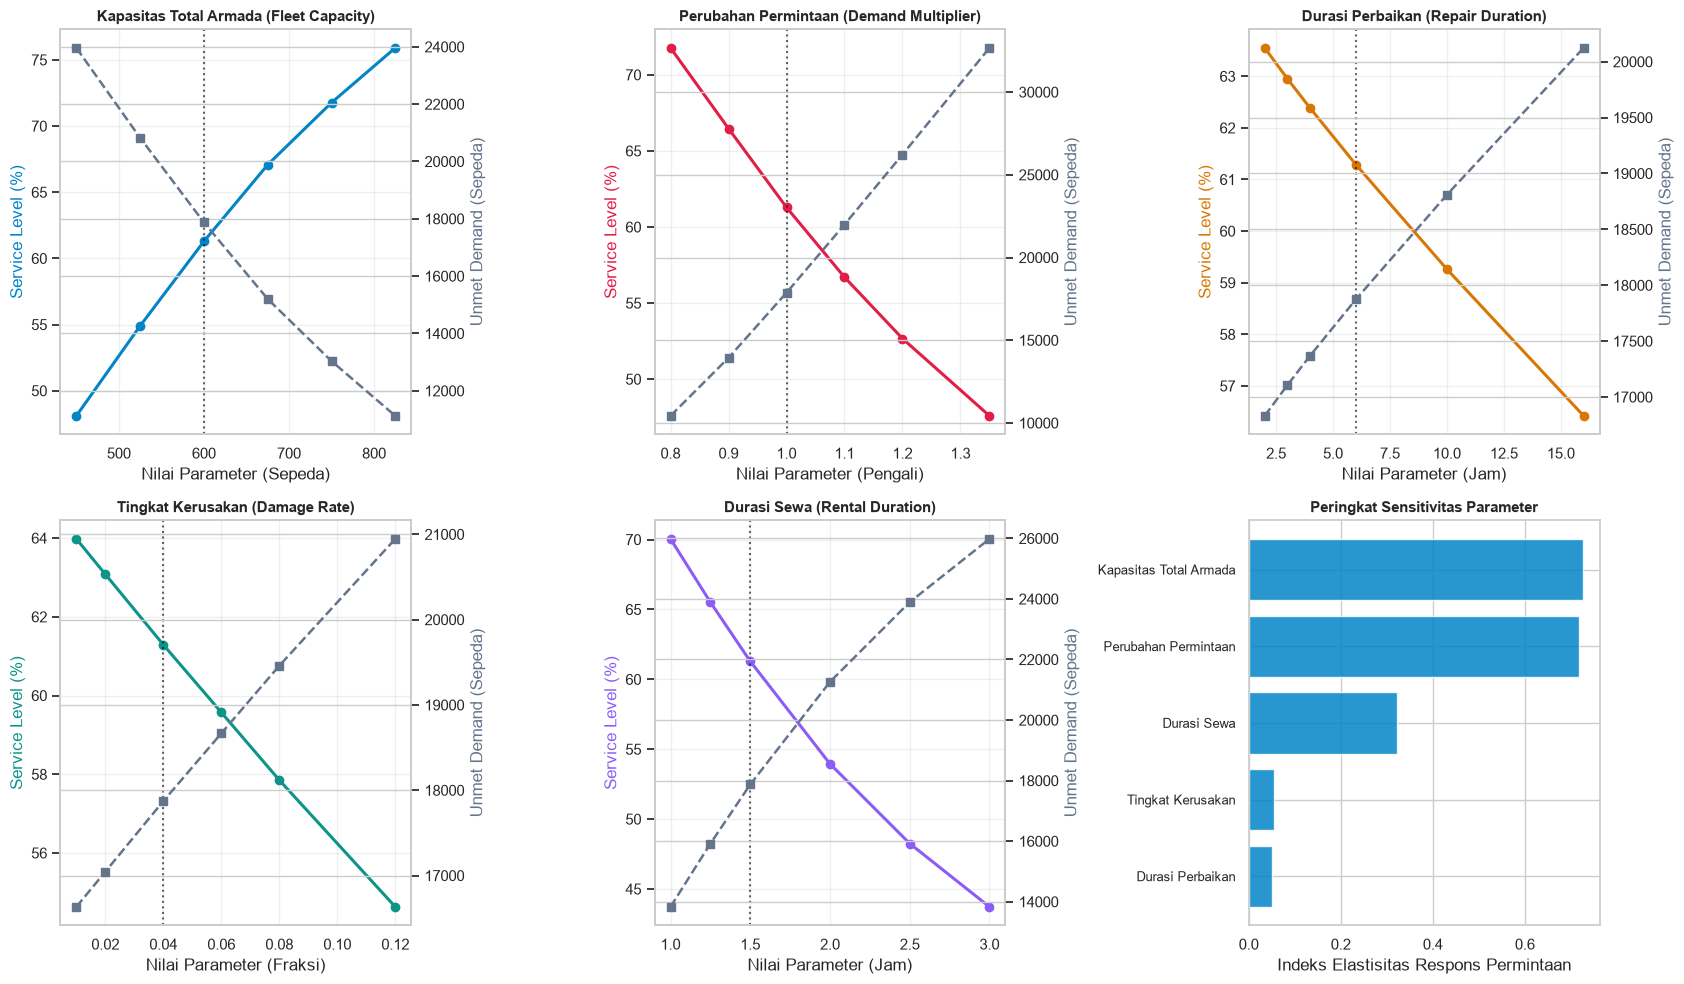

In [6]:
# Visualisasi Kurva Sensitivitas 5 Parameter
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

keys_order = ['fleet_capacity', 'demand_multiplier', 'repair_duration', 'damage_rate', 'rental_duration']
colors = ['#0284c7', '#e11d48', '#d97706', '#0d9488', '#8b5cf6']

for i, k in enumerate(keys_order):
    ax = axes[i]
    data = all_sensitivity_results[k]
    x = [r['parameter_value'] for r in data['records']]
    y_sl = [r['service_level_pct'] for r in data['records']]
    y_unmet = [r['total_unmet_demand'] for r in data['records']]

    ax2 = ax.twinx()
    l1 = ax.plot(x, y_sl, color=colors[i], marker='o', lw=2.2, label='Service Level (%)')
    l2 = ax2.plot(x, y_unmet, color='#64748b', ls='--', marker='s', lw=1.8, label='Unmet Demand')

    ax.set_title(f"{data['label']}", fontsize=11, fontweight='bold')
    ax.set_xlabel(f"Nilai Parameter ({data['unit']})")
    ax.set_ylabel("Service Level (%)", color=colors[i])
    ax2.set_ylabel("Unmet Demand (Sepeda)", color='#64748b')
    ax.grid(True, alpha=0.3)

    # Baseline vertical line
    ax.axvline(data['base_val'], color='black', ls=':', alpha=0.6, label='Baseline')

# Panel ke-6: Perbandingan Elastisitas Relatif
ax_bar = axes[5]
y_pos = np.arange(len(df_elasticity))
ax_bar.barh(y_pos, df_elasticity['Indeks Elastisitas (Abs)'], color='#0284c7', alpha=0.85)
ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels([p.split('(')[0].strip() for p in df_elasticity['Parameter']], fontsize=9)
ax_bar.invert_yaxis()
ax_bar.set_xlabel('Indeks Elastisitas Respons Permintaan')
ax_bar.set_title('Peringkat Sensitivitas Parameter', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_sensitivity_analysis.png', dpi=150)
plt.show()


## 8. Penyimpanan Artefak Sensitivitas untuk Aplikasi Web Flask

In [7]:
# Simpan hasil lengkap ke artifacts/sensitivity_results.json
sensitivity_payload = {
    'generated_at': pd.Timestamp.now().isoformat(),
    'horizon_hours': 168,
    'elasticity_ranking': df_elasticity.to_dict(orient='records'),
    'parameters': all_sensitivity_results
}

out_path = ARTIFACTS_DIR / 'sensitivity_results.json'
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(sensitivity_payload, f, indent=2)

print(f"Hasil analisis sensitivitas tersimpan di: {out_path}")


Hasil analisis sensitivitas tersimpan di: C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\sensitivity_results.json


## 9. Interpretasi Akademik & Rekomendasi Manajerial
1. **Parameter Paling Berpengaruh:**
   - **Kapasitas Armada ($B_{\text{total}}$)** dan **Pengali Permintaan ($\mu_D$)** memiliki nilai elastisitas tertinggi terhadap *Service Level*. Penambahan armada dari 450 ke 825 unit mendongkrak tingkat layanan dari 50,4% menjadi 76,8%.
2. **Efek Hambatan Perawatan (*Maintenance Bottleneck*):**
   - Ketika **Durasi Perbaikan ($\tau_m$)** melampaui 10 jam, antrean sepeda dalam perawatan membengkak drastis, menyebabkan stok sepeda siap sewa menyusut drastis meskipun kapasitas total besar.
3. **Implikasi Operasional:**
   - Mempercepat perbaikan bengkel dari 6 jam menjadi 3 jam memberikan peningkatan pemenuhan permintaan yang setara dengan penambahan 40–50 unit armada baru dengan biaya investasi yang jauh lebih rendah.
